# TP03: your first neural network

**MSA-DATB09-03 · Neural Networks & Deep Learning Foundations · Session 3 / 8** · Guillaume Saint-Cirgue

*Estimated time: 80 minutes*

In the course we stacked neurons into layers: a hidden layer draws several lines, an output neuron combines
them, and XOR becomes possible. We derived backpropagation by hand (the chain rule, layer by layer) and saw
that PyTorch's `loss.backward()` computes exactly the same gradients. In this notebook you check all of it in
code: the XOR network, one forward and backward pass by hand, then real networks trained with PyTorch.

**How it works.** Each exercise is a cell with a zone to complete:

```python
### START CODE HERE ###

### END CODE HERE ###
```

Write your code between the two markers, then run the cell: the `assert` lines below the zone check your
answer and print `Exercise validated!` when it is correct. If an assert fails, read its message: it tells
you what to look at.

**Run it** on Google Colab (File > Upload notebook) or locally with the course `requirements.txt`.

## Imports

- `numpy`: arrays, for the networks computed by hand (Parts A and B).
- `matplotlib`: plots of decision boundaries.
- `torch`, `torch.nn`: PyTorch, its tensors with autograd and its layers (Parts B to D).
- `sklearn.datasets`: `make_moons` and `make_circles`, two 2-D datasets that no line can separate.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_moons, make_circles

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: quick check run
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)                              # small models: 2 CPU threads are enough

## Helper functions (run this cell, no need to modify it)

- `plot_boundary(model, X, y, title, ax)` colours the plane with the probability predicted by a PyTorch model
  and draws its decision boundary (probability 0.5).
- `step` and `sigmoid` are the two activations of the previous sessions, in NumPy.

In [2]:
def step(z):
    return (np.asarray(z) >= 0).astype(int)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def plot_boundary(model, X, y, title="", ax=None):
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))
    x1, x2 = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200))
    grid = torch.tensor(np.c_[x1.ravel(), x2.ravel()], dtype=torch.float32)
    with torch.no_grad():
        P = torch.sigmoid(model(grid)).numpy().reshape(x1.shape)
    ax.contourf(x1, x2, P, levels=np.linspace(0, 1, 11), cmap="coolwarm_r", alpha=0.3)
    ax.contour(x1, x2, P, levels=[0.5], colors="k")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="#4338ca", s=12)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="#d97706", s=12, marker="s")
    ax.set_title(title)
    if show:
        plt.show()

# Part A: the XOR network, with the weights of exercise 1

Reminder of the course: XOR = AND(OR, NAND). Hidden neuron 1 computes OR ($w = (1, 1)$, $b = -0.5$),
hidden neuron 2 computes NAND ($w = (-1, -1)$, $b = 1.5$), the output neuron computes AND of the two
($w = (1, 1)$, $b = -1.5$).

In code, examples are **rows**: `X` has shape `(m, n_in)`, and a layer with weight matrix `W` of shape
`(n_out, n_in)` (one row per neuron) and bias `b` of shape `(n_out,)` computes `X @ W.T + b`, shape
`(m, n_out)`. This is exactly what PyTorch's `nn.Linear` does.

### Exercise 1: a dense layer

Write `dense(X, W, b, activation)` that returns `activation(X @ W.T + b)`. `activation` is a function
(for example `step` or `sigmoid`): you call it like any function.

In [3]:
def dense(X, W, b, activation):
    ### START CODE HERE ###
    A = activation(X @ W.T + b)     # (m, n_in) @ (n_in, n_out) + (n_out,)  ->  (m, n_out)
    ### END CODE HERE ###
    return A


X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
out = dense(X_xor, np.array([[1, 1]]), np.array([-1.5]), step)
assert out.shape == (4, 1), f"one row per example, one column per neuron: expected (4, 1), got {np.shape(out)}"
assert out.ravel().tolist() == [0, 0, 0, 1], "w = (1, 1), b = -1.5 with a step computes AND"
print("Exercise validated!")

Exercise validated!


💡 **Explication en français (exercice 1) : une couche dense**

Une couche fait, pour **tous ses neurones et tous les exemples d'un coup**, ce qu'un neurone faisait en session 2 : un score, puis une activation.

| Objet | Forme | Ce que c'est |
|---|---|---|
| `X` | (m, n_in) | une ligne par exemple, une colonne par entrée |
| `W` | (n_out, n_in) | une ligne par neurone, une colonne par entrée |
| `b` | (n_out,) | un biais par neurone |
| `X @ W.T + b` | (m, n_out) | une ligne par exemple, une colonne par neurone : les scores $z$ |

- **Pourquoi `W.T` ?** Pour que les dimensions s'emboîtent : (m, n_in) @ (n_in, n_out) donne (m, n_out). La case (exemple $i$, neurone $k$) vaut $X_{i1} W_{k1} + X_{i2} W_{k2}$ : le score du neurone $k$ pour l'exemple $i$ (sans le biais).
- **`+ b`** : NumPy ajoute `b` à **chaque ligne** (c'est le « broadcasting ») : chaque neurone reçoit son biais, pour chaque exemple.
- **`activation(...)`** : `activation` est une variable qui contient une **fonction** (`step` ou `sigmoid`). On l'appelle comme n'importe quelle fonction.

**Le test** : avec $w = (w_1, w_2) = (1, 1)$ et $b = -1.5$, le score est $z = w_1 x_1 + w_2 x_2 + b = 1 \times x_1 + 1 \times x_2 - 1.5$. Il n'est positif que pour $x = (1, 1)$ : $z = 1 + 1 - 1.5 = 0.5$. La couche calcule bien AND : $(0, 0, 0, 1)$.

### Exercise 2: the weights of the XOR network

Create `W1` (shape `(2, 2)`: row 0 = the OR neuron, row 1 = the NAND neuron), `b1` (shape `(2,)`), `W2`
(shape `(1, 2)`: the AND neuron) and `b2` (shape `(1,)`), as float arrays.

In [4]:
### START CODE HERE ###
W1 = np.array([[1.0, 1.0],      # ligne 0 : le neurone OR,   w = (1, 1)
               [-1.0, -1.0]])   # ligne 1 : le neurone NAND, w = (-1, -1)
b1 = np.array([-0.5, 1.5])      # biais du neurone OR, biais du neurone NAND
W2 = np.array([[1.0, 1.0]])     # le neurone AND (une seule ligne : un seul neurone)
b2 = np.array([-1.5])           # biais du neurone AND
### END CODE HERE ###

assert W1.shape == (2, 2) and b1.shape == (2,), "layer 1: W1 of shape (2, 2), b1 of shape (2,)"
assert W2.shape == (1, 2) and b2.shape == (1,), "layer 2: W2 of shape (1, 2), b2 of shape (1,)"
assert dense(X_xor, W1[:1], b1[:1], step).ravel().tolist() == [0, 1, 1, 1], "row 0 of W1 (with b1[0]) must compute OR"
assert dense(X_xor, W1[1:], b1[1:], step).ravel().tolist() == [1, 1, 1, 0], "row 1 of W1 (with b1[1]) must compute NAND"
print("Exercise validated!")

Exercise validated!


💡 **Explication (exercice 2) : ranger les poids**

Règle : **une ligne de `W` = un neurone**, et la ligne contient ses poids dans l'ordre des entrées $(x_1, x_2)$.

| Neurone | Où | Poids $(w_1, w_2)$ | Biais |
|---|---|---|---|
| OR | ligne 0 de `W1` | (1, 1) | `b1[0]` = -0.5 |
| NAND | ligne 1 de `W1` | (-1, -1) | `b1[1]` = 1.5 |
| AND | ligne 0 de `W2` (la seule) | (1, 1) | `b2[0]` = -1.5 |

- `W2` s'écrit `[[1.0, 1.0]]` avec **deux** paires de crochets : c'est une matrice d'**une ligne** (forme (1, 2)), pas un vecteur (forme (2,)).
- On écrit `1.0` plutôt que `1` pour avoir des **floats** (nombres à virgule), comme demandé.
- Dans le test, `W1[:1]` garde seulement la ligne 0 **en restant une matrice** (forme (1, 2)), pour tester le neurone OR tout seul.

### Exercise 3: the forward pass of the network

Write `forward_xor(X, activation)` that returns the hidden layer output `A1` (shape `(m, 2)`) and the network
output `A2` (shape `(m, 1)`), using `dense` twice with the weights above.

In [5]:
def forward_xor(X, activation=step):
    ### START CODE HERE ###
    A1 = dense(X, W1, b1, activation)     # couche cachée : (m, 2)
    A2 = dense(A1, W2, b2, activation)    # sortie : son entrée est A1, PAS X ; (m, 1)
    ### END CODE HERE ###
    return A1, A2


A1, A2 = forward_xor(X_xor)
print("hidden layer:\n", A1, "\noutput:", A2.ravel())
assert A1.tolist() == [[0, 1], [1, 1], [1, 1], [1, 0]], "the hidden representation of exercise 1 is (0,1), (1,1), (1,1), (1,0)"
assert A2.ravel().tolist() == [0, 1, 1, 0], "the network must compute XOR"
print("Exercise validated!")

hidden layer:
 [[0 1]
 [1 1]
 [1 1]
 [1 0]] 
output: [0 1 1 0]
Exercise validated!


💡 **Explication (exercice 3) : enchaîner les deux couches**

Le forward d'un réseau, c'est appeler `dense` **une fois par couche**, en donnant à chaque couche **la sortie de la précédente** :

$$A^{[1]} = \text{step}\big(X\,W^{[1]\top} + b^{[1]}\big) \qquad A^{[2]} = \text{step}\big(A^{[1]}\,W^{[2]\top} + b^{[2]}\big)$$

⚠️ L'erreur classique : écrire `dense(X, W2, ...)` pour la 2e couche. Son entrée est `A1` (les 2 neurones cachés), pas `X`.

Les formes : `X` (4, 2), puis `A1` (4, 2), puis `A2` (4, 1). On retrouve la représentation cachée de la slide 6 : $(0, 1), (1, 1), (1, 1), (1, 0)$, puis le XOR $(0, 1, 1, 0)$.

**What we see.** The hidden layer maps the 4 inputs to only 3 distinct points, and in this new space one
line (the AND neuron) separates the classes. The hidden layer has built the features that make the problem
easy.

### Exercise 4: the same network with sigmoids

A step has no gradient, so we cannot train it. Replace it by a sigmoid and multiply **all** weights and
biases by 10 (question 2 of exercise 1). Compute `A2_sig`, the output for the 4 inputs (shape `(4, 1)`).

> Hint: you cannot reuse `forward_xor` directly because the weights change; call `dense` twice with
> `10 * W1`, `10 * b1`, and so on.

In [6]:
### START CODE HERE ###
A1_sig = dense(X_xor, 10 * W1, 10 * b1, sigmoid)    # couche cachée, poids et biais x10
A2_sig = dense(A1_sig, 10 * W2, 10 * b2, sigmoid)   # sortie, poids et biais x10
### END CODE HERE ###

print("outputs:", A2_sig.ravel().round(4))
assert A2_sig.shape == (4, 1), "one output per example"
assert np.isclose(A2_sig[1, 0], 0.9924, atol=1e-3), "for x = (0, 1) the course gives 0.992"
assert np.all(np.abs(A2_sig.ravel() - y_xor) < 0.01), "the sigmoid network should be within 0.01 of XOR"
print("Exercise validated!")

outputs: [0.0072 0.9924 0.9924 0.0072]
Exercise validated!


💡 **Explication (exercice 4) : sigmoïde et poids ×10**

- **Pourquoi la sigmoïde** : la marche a une pente nulle partout, donc on ne peut pas l'entraîner. La sigmoïde a une pente.
- **Pourquoi ×10** : multiplier **tous** les poids et le biais d'un neurone par 10 multiplie son score par 10 : $(10\,w_1) x_1 + (10\,w_2) x_2 + 10\,b = 10\,z$. Et $\sigma(10\,z)$ est une sigmoïde très raide, presque une marche.

Pour $x = (x_1, x_2) = (0, 1)$, avec $z = w_1 x_1 + w_2 x_2 + b$ pour chaque neurone :

- neurone OR ($w = (10, 10)$, $b = -5$) : $z_1 = 10 \times 0 + 10 \times 1 + (-5) = 5$, donc $h_1 = \sigma(5) \approx 0.993$
- neurone NAND ($w = (-10, -10)$, $b = 15$) : $z_2 = (-10) \times 0 + (-10) \times 1 + 15 = 5$, donc $h_2 = \sigma(5) \approx 0.993$
- neurone AND ($w = (10, 10)$, $b = -15$, ses entrées sont $h_1, h_2$) : $z = 10 \times 0.993 + 10 \times 0.993 + (-15) \approx 4.87$, donc $\hat{y} = \sigma(4.87) \approx 0.992$

On obtient $(0.0072,\ 0.9924,\ 0.9924,\ 0.0072)$ : presque exactement XOR, avec une fonction dérivable. La couche cachée s'appelle `A1_sig` pour ne pas écraser le `A1` de l'exercice 3.

# Part B: one forward and one backward pass by hand

Exercise 3 of the course: a 2-2-1 network with sigmoids and one example $x = (1, 2)$, $y = 1$. For one
example we work with 1-D arrays (the column vectors of the slides): $z^{[1]} = W^{[1]} x + b^{[1]}$ is
`W1 @ x + b1` in NumPy.

In [7]:
x_ex = np.array([1.0, 2.0])
y_ex = 1.0
W1_ex = np.array([[1.0, -1.0], [0.5, 0.5]])
b1_ex = np.array([1.0, -1.5])
W2_ex = np.array([[1.0, -1.0]])
b2_ex = np.array([0.0])

### Exercise 5: the forward pass

Write `forward_one(x, W1, b1, W2, b2)` that returns `z1, a1, z2, a2`:

$$ z^{[1]} = W^{[1]} x + b^{[1]}, \quad a^{[1]} = \sigma(z^{[1]}), \quad z^{[2]} = W^{[2]} a^{[1]} + b^{[2]}, \quad a^{[2]} = \sigma(z^{[2]}) $$

- `W @ v` with `W` of shape `(k, n)` and `v` of shape `(n,)` gives a vector of shape `(k,)`.

In [8]:
def forward_one(x, W1, b1, W2, b2):
    ### START CODE HERE ###
    z1 = W1 @ x + b1        # (2,) : un score par neurone caché
    a1 = sigmoid(z1)        # (2,)
    z2 = W2 @ a1 + b2       # (1,) : le score du neurone de sortie, son entrée est a1
    a2 = sigmoid(z2)        # (1,)
    ### END CODE HERE ###
    return z1, a1, z2, a2


z1, a1, z2, a2 = forward_one(x_ex, W1_ex, b1_ex, W2_ex, b2_ex)
print("z1 =", z1, " a1 =", a1, " z2 =", z2, " a2 =", a2)
assert np.allclose(z1, [0, 0]) and np.allclose(a1, [0.5, 0.5]), "z1 should be (0, 0), so a1 = (0.5, 0.5)"
assert np.shape(a2) == (1,) and np.isclose(a2[0], 0.5), "a2 should be an array of shape (1,) equal to 0.5"
print("Exercise validated!")

z1 = [0. 0.]  a1 = [0.5 0.5]  z2 = [0.]  a2 = [0.5]
Exercise validated!


💡 **Explication (exercice 5) : le forward pour un exemple**

Ici un seul exemple, rangé dans un vecteur 1-D `x` de forme (2,) (la « colonne » des slides). Le code suit les 4 formules ligne par ligne :

| Formule | Code | Formes |
|---|---|---|
| $z^{[1]} = W^{[1]}x + b^{[1]}$ | `z1 = W1 @ x + b1` | (2, 2) @ (2,) + (2,) donne (2,) |
| $a^{[1]} = \sigma(z^{[1]})$ | `a1 = sigmoid(z1)` | (2,) |
| $z^{[2]} = W^{[2]}a^{[1]} + b^{[2]}$ | `z2 = W2 @ a1 + b2` | (1, 2) @ (2,) + (1,) donne (1,) |
| $a^{[2]} = \sigma(z^{[2]})$ | `a2 = sigmoid(z2)` | (1,) |

Avec les valeurs de l'exercice 3 du cours :

- neurone caché 1 : $z^{[1]}_1 = W^{[1]}_{11} x_1 + W^{[1]}_{12} x_2 + b^{[1]}_1 = 1 \times 1 + (-1) \times 2 + 1 = 0$
- neurone caché 2 : $z^{[1]}_2 = W^{[1]}_{21} x_1 + W^{[1]}_{22} x_2 + b^{[1]}_2 = 0.5 \times 1 + 0.5 \times 2 + (-1.5) = 0$
- donc $a^{[1]} = (0.5, 0.5)$, puis $z^{[2]} = W^{[2]}_1 a^{[1]}_1 + W^{[2]}_2 a^{[1]}_2 + b^{[2]} = 1 \times 0.5 + (-1) \times 0.5 + 0 = 0$ et $a^{[2]} = 0.5$

Le détail complet, variable par variable, est dans `Session3_exercices_expliques.ipynb` (exercice 3).

### Exercise 6: the loss

Write `loss_one(a2, y)`: the log loss $\mathcal{L} = -[y \log a^{[2]} + (1 - y)\log(1 - a^{[2]})]$ of this
example, returned as a Python number (`float(...)`, since `a2` has shape `(1,)`).

In [9]:
def loss_one(a2, y):
    ### START CODE HERE ###
    L = float(-(y * np.log(a2[0]) + (1 - y) * np.log(1 - a2[0])))   # a2[0] : la seule valeur de a2
    ### END CODE HERE ###
    return L


L0 = loss_one(a2, y_ex)
assert isinstance(L0, float), "return a Python float"
assert np.isclose(L0, np.log(2)), "with a2 = 0.5 the loss is log 2 = 0.693"
print("Exercise validated!")

Exercise validated!


💡 **Explication (exercice 6) : la loss**

$$\mathcal{L} = -\big[y \log a^{[2]} + (1 - y)\log(1 - a^{[2]})\big] = -\big[1 \times \log 0.5 + 0 \times \log 0.5\big] = \log 2 \approx 0.693$$

- `a2` est un tableau de forme (1,) : `a2[0]` en extrait **la seule valeur** (un nombre).
- `float(...)` convertit le résultat en nombre Python, comme le test l'exige.
- `np.log` est le logarithme naturel (ln).

### Exercise 7: the backward pass

Write `backward_one(x, y, W2, a1, a2)` with the formulas of the course:

$$ dz^{[2]} = a^{[2]} - y, \qquad dW^{[2]} = dz^{[2]}\, a^{[1]\top}, \qquad db^{[2]} = dz^{[2]} $$
$$ da^{[1]} = W^{[2]\top} dz^{[2]}, \qquad dz^{[1]} = da^{[1]} \odot a^{[1]} \odot (1 - a^{[1]}), \qquad dW^{[1]} = dz^{[1]}\, x^\top, \qquad db^{[1]} = dz^{[1]} $$

- $u\,v^\top$ for two vectors is their **outer product**, a matrix: `np.outer(u, v)` (shape `(len(u), len(v))`).
  Do not use `u @ v`, which is a dot product (a number).
- `W2.T @ dz2` sends the output error back to the hidden neurons; `*` is the element-wise product $\odot$.

In [10]:
def backward_one(x, y, W2, a1, a2):
    ### START CODE HERE ###
    # Couche de sortie
    dz2 = a2 - y                    # (1,)   l'erreur
    dW2 = np.outer(dz2, a1)         # (1, 2) erreur x entrée (produit extérieur)
    db2 = dz2                       # (1,)
    # Retour vers la couche cachée
    da1 = W2.T @ dz2                # (2,)   l'erreur renvoyée à chaque neurone caché
    dz1 = da1 * a1 * (1 - a1)       # (2,)   on traverse la sigmoïde (* = produit élément par élément)
    dW1 = np.outer(dz1, x)          # (2, 2)
    db1 = dz1                       # (2,)
    ### END CODE HERE ###
    return dW1, db1, dW2, db2


dW1, db1, dW2, db2 = backward_one(x_ex, y_ex, W2_ex, a1, a2)
print("dW2 =", dW2, " db2 =", db2)
print("dW1 =\n", dW1, "\ndb1 =", db1)
assert np.shape(dW2) == W2_ex.shape and np.shape(dW1) == W1_ex.shape, "each gradient has the shape of its parameter"
assert np.allclose(dW2, [[-0.25, -0.25]]) and np.allclose(db2, [-0.5]), "output layer: dW2 = (-0.25, -0.25), db2 = -0.5"
assert np.allclose(dW1, [[-0.125, -0.25], [0.125, 0.25]]), "hidden layer: see the solution of exercise 3"
assert np.allclose(db1, [-0.125, 0.125]), "db1 = dz1 = (-0.125, 0.125)"
print("Exercise validated!")

dW2 = [[-0.25 -0.25]]  db2 = [-0.5]
dW1 =
 [[-0.125 -0.25 ]
 [ 0.125  0.25 ]] 
db1 = [-0.125  0.125]
Exercise validated!


💡 **Explication (exercice 7) : le backward**

Chaque ligne de code est une formule du cours :

| Formule | Code | Calcul |
|---|---|---|
| $dz^{[2]} = a^{[2]} - y$ | `dz2 = a2 - y` | $0.5 - 1 = -0.5$ |
| $dW^{[2]} = dz^{[2]}\, a^{[1]\top}$ | `dW2 = np.outer(dz2, a1)` | $(-0.5 \times 0.5,\ -0.5 \times 0.5) = (-0.25,\ -0.25)$ |
| $db^{[2]} = dz^{[2]}$ | `db2 = dz2` | $-0.5$ |
| $da^{[1]} = W^{[2]\top} dz^{[2]}$ | `da1 = W2.T @ dz2` | $(1 \times (-0.5),\ (-1) \times (-0.5)) = (-0.5,\ 0.5)$ |
| $dz^{[1]} = da^{[1]} \odot a^{[1]} \odot (1 - a^{[1]})$ | `dz1 = da1 * a1 * (1 - a1)` | $(-0.5 \times 0.5 \times 0.5,\ 0.5 \times 0.5 \times 0.5) = (-0.125,\ 0.125)$ |
| $dW^{[1]} = dz^{[1]}\, x^\top$ | `dW1 = np.outer(dz1, x)` | [[-0.125, -0.25], [0.125, 0.25]] |
| $db^{[1]} = dz^{[1]}$ | `db1 = dz1` | $(-0.125,\ 0.125)$ |

Trois opérations à ne pas confondre :

- `np.outer(u, v)` : produit **extérieur**, une matrice dont la case $(k, j)$ vaut $u_k \times v_j$ (« erreur du neurone $k$ × entrée $j$ ») ;
- `W2.T @ dz2` : produit **matriciel** (on multiplie puis on additionne), il renvoie l'erreur vers chaque neurone caché ;
- `*` : produit **élément par élément** ($\odot$), case par case, sans additionner.

### Exercise 8: check with finite differences

As in TP02, check two entries of the gradient numerically:

$$ \frac{\partial \mathcal{L}}{\partial W^{[1]}_{11}} \approx \frac{\mathcal{L}(W^{[1]}_{11} + h) - \mathcal{L}(W^{[1]}_{11} - h)}{2h} $$

Compute `num_W1_00` (for `W1_ex[0, 0]`) and `num_W2_01` (for `W2_ex[0, 1]`) with `h = 1e-5`. The helper
`loss_of` computes the loss for given parameters. Work on copies (`W.copy()`): never modify `W1_ex` itself.

In [11]:
def loss_of(W1, b1, W2, b2):
    return loss_one(forward_one(x_ex, W1, b1, W2, b2)[3], y_ex)


h = 1e-5
### START CODE HERE ###
# W1[0, 0] : on fait deux COPIES, une décalée de +h, l'autre de -h
W1_plus, W1_minus = W1_ex.copy(), W1_ex.copy()
W1_plus[0, 0] += h
W1_minus[0, 0] -= h
num_W1_00 = (loss_of(W1_plus, b1_ex, W2_ex, b2_ex) - loss_of(W1_minus, b1_ex, W2_ex, b2_ex)) / (2 * h)

# W2[0, 1] : même chose
W2_plus, W2_minus = W2_ex.copy(), W2_ex.copy()
W2_plus[0, 1] += h
W2_minus[0, 1] -= h
num_W2_01 = (loss_of(W1_ex, b1_ex, W2_plus, b2_ex) - loss_of(W1_ex, b1_ex, W2_minus, b2_ex)) / (2 * h)
### END CODE HERE ###

print("numerical:", num_W1_00, num_W2_01, " backprop:", dW1[0, 0], dW2[0, 1])
assert np.allclose(W1_ex, [[1, -1], [0.5, 0.5]]) and np.allclose(W2_ex, [[1, -1]]), "do not modify W1_ex or W2_ex"
assert np.isclose(num_W1_00, dW1[0, 0], atol=1e-8), "the finite difference should match dW1[0, 0]"
assert np.isclose(num_W2_01, dW2[0, 1], atol=1e-8), "the finite difference should match dW2[0, 1]"
print("Exercise validated!")

numerical: -0.12500000000637002 -0.24999999999608666  backprop: -0.125 -0.25
Exercise validated!


💡 **Explication (exercice 8) : les différences finies**

L'idée : mesurer la pente « à la main ». On bouge **un seul** poids d'un tout petit $h$ vers le haut, puis vers le bas, et on regarde de combien la loss change :

$$\frac{\partial \mathcal{L}}{\partial W^{[1]}_{11}} \approx \frac{\mathcal{L}(W^{[1]}_{11} + h) - \mathcal{L}(W^{[1]}_{11} - h)}{2h}$$

- `W1_ex[0, 0]` en Python est le $W^{[1]}_{11}$ du cours (les indices Python commencent à 0) ; `W2_ex[0, 1]` est $W^{[2]}_2$.
- **Pourquoi `.copy()`** : en Python, `W1_plus = W1_ex` ne crée **pas** un nouveau tableau, juste un deuxième nom pour le même. Modifier `W1_plus[0, 0]` modifierait aussi `W1_ex`. `.copy()` crée un vrai tableau indépendant.
- On divise par $2h$ parce que l'écart entre $W + h$ et $W - h$ vaut $2h$.

Résultat : $-0.125$ et $-0.25$, exactement les `dW1[0, 0]` et `dW2[0, 1]` de la backpropagation. Nos formules sont justes.

### Exercise 9: PyTorch's autograd gives the same gradients

Create the four parameters as float64 tensors that require a gradient (`torch.tensor(W1_ex,
requires_grad=True)` keeps the float64 type of the NumPy array), redo the forward pass with
`torch.sigmoid` and the loss with `torch.log`, then call `loss_t.backward()`. Each `param.grad` is then
filled with $\partial \mathcal{L} / \partial \text{param}$.

- The tensor operations are the same as in NumPy: `W1_t @ x_t + b1_t`.
- `loss_t` must be a single number (a 0-dimensional tensor): use `.sum()` at the end, since `a2` has
  shape `(1,)`.

In [12]:
x_t = torch.tensor(x_ex)
### START CODE HERE ###
# Les 4 paramètres, en float64 (le type des tableaux NumPy), avec suivi du gradient
W1_t = torch.tensor(W1_ex, requires_grad=True)
b1_t = torch.tensor(b1_ex, requires_grad=True)
W2_t = torch.tensor(W2_ex, requires_grad=True)
b2_t = torch.tensor(b2_ex, requires_grad=True)

# Forward : le même calcul qu'en NumPy, PyTorch enregistre chaque opération
a1_t = torch.sigmoid(W1_t @ x_t + b1_t)
a2_t = torch.sigmoid(W2_t @ a1_t + b2_t)
loss_t = -(y_ex * torch.log(a2_t) + (1 - y_ex) * torch.log(1 - a2_t)).sum()   # .sum() : un seul nombre

# Backward : PyTorch applique la règle de la chaîne et remplit W1_t.grad, b1_t.grad, ...
loss_t.backward()
### END CODE HERE ###

print("autograd dW1:\n", W1_t.grad, "\nautograd dW2:", W2_t.grad)
assert W1_t.grad is not None, "call loss_t.backward()"
assert np.allclose(W1_t.grad.numpy(), dW1) and np.allclose(b1_t.grad.numpy(), db1), "layer 1: autograd = backprop by hand"
assert np.allclose(W2_t.grad.numpy(), dW2) and np.allclose(b2_t.grad.numpy(), db2), "layer 2: autograd = backprop by hand"
print("Exercise validated! loss.backward() computes exactly the chain rule you wrote.")

autograd dW1:
 tensor([[-0.1250, -0.2500],
        [ 0.1250,  0.2500]], dtype=torch.float64) 
autograd dW2: tensor([[-0.2500, -0.2500]], dtype=torch.float64)
Exercise validated! loss.backward() computes exactly the chain rule you wrote.


💡 **Explication (exercice 9) : l'autograd de PyTorch**

- `torch.tensor(W1_ex, requires_grad=True)` crée un tenseur à partir du tableau NumPy (il garde le type float64) et demande à PyTorch d'**enregistrer** toutes les opérations faites avec lui.
- Le forward s'écrit exactement comme en NumPy (`@`, `torch.sigmoid`, `torch.log`).
- `.sum()` : `a2_t` a la forme (1,), donc la loss aussi. Or `backward()` doit partir d'**un seul nombre** (un tenseur à 0 dimension) : `.sum()` transforme ce tableau d'une case en un nombre.
- `loss_t.backward()` parcourt le graphe enregistré **à l'envers** (de la loss vers les paramètres), applique la règle de la chaîne, et range $\partial \mathcal{L} / \partial W^{[1]}$ dans `W1_t.grad`, et ainsi de suite pour les 4 paramètres.

PyTorch trouve exactement les mêmes gradients que notre backward à la main : `loss.backward()` **est** la backpropagation.

### Exercise 10: one gradient step

Update the four NumPy parameters with $\eta = 1$ (`W1_new = W1_ex - eta * dW1`, and so on), then compute the
new loss `L1` with `loss_of`. The course says it drops from 0.693 to 0.285.

In [13]:
eta = 1.0
### START CODE HERE ###
W1_new = W1_ex - eta * dW1      # chaque case : ancienne valeur - eta x gradient de la même case
b1_new = b1_ex - eta * db1
W2_new = W2_ex - eta * dW2
b2_new = b2_ex - eta * db2
L1 = loss_of(W1_new, b1_new, W2_new, b2_new)
### END CODE HERE ###

print("new loss:", round(L1, 3))
assert np.allclose(W1_new, [[1.125, -0.75], [0.375, 0.25]]), "check the update of W1"
assert np.isclose(L1, 0.2853, atol=1e-3), "the new loss should be 0.285"
print("Exercise validated!")

new loss: 0.285
Exercise validated!


💡 **Explication (exercice 10) : un pas de gradient**

Descente de gradient, case par case : $W \leftarrow W - \eta\, dW$. Avec $\eta = 1$, on soustrait simplement les gradients. Par exemple :

$$W^{[1]}_{11} \leftarrow W^{[1]}_{11} - \eta\, dW^{[1]}_{11} = 1 - 1 \times (-0.125) = 1.125$$

Nouveaux paramètres : $W^{[1]}$ = [[1.125, -0.75], [0.375, 0.25]], $b^{[1]} = (1.125,\ -1.625)$, $W^{[2]} = (1.25,\ -0.75)$, $b^{[2]} = 0.5$.

`loss_of` refait le forward avec ces paramètres : la loss passe de **0.693 à 0.285** en un seul pas (la prédiction $a^{[2]}$ passe de 0.5 à 0.752, la bonne réponse étant 1).

**Going further on your own.** Coding a full neural network from scratch in NumPy (forward and backward,
layer by layer, with a training loop) is a great exercise: I do it step by step on my YouTube channel
Machine Learnia, in video 9 of the Deep Learning series (in French):
[Programmer le réseau à 2 couches avec NumPy](https://www.youtube.com/watch?v=LXvSdSKw9dk&list=PLO_fdPEVlfKoanjvTJbIbd9V5d9Pzp8Rw&index=9).
Here we move on to PyTorch, which does the backward pass for us.

# Part C: the network in PyTorch

### Exercise 11: build the network

`nn.Sequential(layer1, layer2, ...)` chains layers: the output of each one is the input of the next.
Build `model` = a 2-3-1 network: `nn.Linear(2, 3)`, then `nn.Sigmoid()`, then `nn.Linear(3, 1)`. No sigmoid
at the end: the loss `BCEWithLogitsLoss` applies it (session 2).

Then count its parameters: `model.parameters()` yields every weight and bias tensor, and `p.numel()` is the
number of elements of tensor `p`. Store the total in `n_params`.

In [14]:
torch.manual_seed(0)
### START CODE HERE ###
model = nn.Sequential(
    nn.Linear(2, 3),    # couche 1 : weight (3, 2), bias (3,)
    nn.Sigmoid(),       # la non-linéarité entre les deux couches
    nn.Linear(3, 1),    # couche 2 : weight (1, 3), bias (1,) ; sa sortie est le logit z
)
n_params = sum(p.numel() for p in model.parameters())   # 6 + 3 + 3 + 1
### END CODE HERE ###

print(model)
assert model[0].weight.shape == (3, 2), "the first layer's weight has shape (n_out, n_in) = (3, 2)"
assert isinstance(model[1], nn.Sigmoid) and model[2].weight.shape == (1, 3), "then a sigmoid, then nn.Linear(3, 1)"
assert n_params == 13, "exercise 2 of the course: 6 + 3 + 3 + 1 = 13 parameters"
print("Exercise validated!")

Sequential(
  (0): Linear(in_features=2, out_features=3, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=3, out_features=1, bias=True)
)
Exercise validated!


💡 **Explication (exercice 11) : le réseau en PyTorch**

- `nn.Sequential(...)` enchaîne les couches : la sortie de l'une est l'entrée de la suivante (comme nos deux appels à `dense`).
- `nn.Linear(2, 3)` : 2 entrées, 3 neurones. Elle contient `weight` de forme **(3, 2)** (sortie, entrée) et `bias` de forme (3,), et calcule `X @ weight.T + bias`.
- `nn.Sigmoid()` : l'activation **entre** les couches. Sans elle, les deux `Linear` se réduiraient à une seule couche linéaire (slide 11).
- **Pas de sigmoïde à la fin** : la sortie est le logit $z$ ; c'est `BCEWithLogitsLoss` qui applique la sigmoïde, de façon stable (session 2).

**Compter les paramètres** : `model.parameters()` donne chaque tenseur de poids et de biais, `p.numel()` son nombre d'éléments, et `sum(...)` additionne tout. Avec la formule $n^{[l]}(n^{[l-1]} + 1)$ par couche :

$$n^{[1]}\big(n^{[0]} + 1\big) + n^{[2]}\big(n^{[1]} + 1\big) = 3 \times (2 + 1) + 1 \times (3 + 1) = 9 + 4 = 13$$

### Exercise 12: the training function

Write `train(model, X_t, y_t, lr, n_epochs)` with the loop of session 2 (full batch: all the examples at
each step):

- create `loss_fn = nn.BCEWithLogitsLoss()` and `optimizer = torch.optim.SGD(model.parameters(), lr=lr)`;
- for each epoch: `optimizer.zero_grad()`, the forward pass `model(X_t).squeeze(1)` (logits of shape `(m,)`),
  the loss, `loss.backward()` (backpropagation through all the layers), `optimizer.step()`;
- append `loss.item()` to the list `losses` and return it.

In [15]:
def train(model, X_t, y_t, lr=5.0, n_epochs=2000):
    losses = []
    ### START CODE HERE ###
    loss_fn = nn.BCEWithLogitsLoss()                         # sigmoïde + log loss, version stable
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)   # descente de gradient sur tous les paramètres
    for epoch in range(n_epochs):
        optimizer.zero_grad()              # 1. remettre les gradients à zéro
        z = model(X_t).squeeze(1)          # 2. forward : logits, (m, 1) -> (m,)
        loss = loss_fn(z, y_t)             # 3. la log loss
        loss.backward()                    # 4. backpropagation dans toutes les couches
        optimizer.step()                   # 5. w <- w - lr x gradient
        losses.append(loss.item())         # la loss comme nombre Python
    ### END CODE HERE ###
    return losses


torch.manual_seed(0)
test_model = nn.Sequential(nn.Linear(2, 3), nn.Sigmoid(), nn.Linear(3, 1))
test_losses = train(test_model, torch.rand(8, 2), torch.ones(8), lr=0.5, n_epochs=50)
assert len(test_losses) == 50, "one loss per epoch"
assert test_losses[-1] < test_losses[0], "the loss must decrease"
print("Exercise validated!")

Exercise validated!


💡 **Explication (exercice 12) : la boucle d'entraînement**

Les 5 lignes que tu écriras dans **tous** les projets PyTorch :

1. `optimizer.zero_grad()` : PyTorch **additionne** les nouveaux gradients aux anciens. Sans cette remise à zéro, ils s'accumuleraient d'une itération à l'autre.
2. `z = model(X_t).squeeze(1)` : le forward. Le modèle sort une forme (m, 1) ; `.squeeze(1)` enlève la dimension de taille 1 pour obtenir (m,), comme `y_t`.
3. `loss = loss_fn(z, y_t)` : la log loss moyenne $J$.
4. `loss.backward()` : la backpropagation, à travers **toutes** les couches.
5. `optimizer.step()` : la mise à jour $w \leftarrow w - \eta\, \nabla J$ pour **tous** les paramètres.

« Full batch » : à chaque itération (epoch), on utilise **tous** les exemples d'un coup. `loss.item()` transforme le tenseur en nombre Python pour le stocker dans la liste.

### Exercise 13: accuracy

Write `accuracy(model, X_t, y_t)`: the fraction of correct predictions, as a Python float. A logit $z > 0$
means a probability above 0.5, so class 1.

- `with torch.no_grad():` evaluates without recording the graph (we do not need gradients here).
- `(z > 0).float()` turns booleans into 0.0/1.0; `.mean().item()` gives a Python number.

In [16]:
def accuracy(model, X_t, y_t):
    ### START CODE HERE ###
    with torch.no_grad():                                   # pas besoin de gradients pour évaluer
        z = model(X_t).squeeze(1)                           # logits, (m,)
        acc = ((z > 0).float() == y_t).float().mean().item()  # z > 0  <=>  probabilité > 0.5  <=>  classe 1
    ### END CODE HERE ###
    return acc


assert accuracy(test_model, torch.rand(8, 2), torch.ones(8)) == 1.0, "the test model always predicts 1 by now"
print("Exercise validated!")

Exercise validated!


💡 **Explication (exercice 13) : la précision (accuracy)**

- `with torch.no_grad():` : on ne fait qu'**évaluer**, pas apprendre. Inutile d'enregistrer le graphe des calculs.
- `z > 0` : un logit positif veut dire $\sigma(z) > 0.5$, donc classe 1 (session 2 : $a \ge 0.5 \iff z \ge 0$).
- `(z > 0).float()` : `True` / `False` deviennent `1.0` / `0.0`, ce sont les classes prédites.
- `== y_t` donne `True` là où la prédiction est juste ; `.float().mean()` fait la **moyenne** de ces 1 et 0, c'est-à-dire la fraction de bonnes réponses.
- `.item()` : en nombre Python.

### Exercise 14: XOR, learnt

Convert the XOR table to float32 tensors `Xx_t` (shape `(4, 2)`) and `yx_t` (shape `(4,)`), create a fresh
2-3-1 network `model_xor` (after `torch.manual_seed(0)`), train it (`lr=5.0`, 2000 epochs) and compute its
accuracy `acc_xor`.

In [17]:
### START CODE HERE ###
Xx_t = torch.tensor(X_xor, dtype=torch.float32)   # (4, 2)
yx_t = torch.tensor(y_xor, dtype=torch.float32)   # (4,)
torch.manual_seed(0)                              # même départ aléatoire pour tout le monde
model_xor = nn.Sequential(nn.Linear(2, 3), nn.Sigmoid(), nn.Linear(3, 1))
losses_xor = train(model_xor, Xx_t, yx_t, lr=5.0, n_epochs=2000)
acc_xor = accuracy(model_xor, Xx_t, yx_t)
### END CODE HERE ###

print("final loss:", round(losses_xor[-1], 4), " accuracy:", acc_xor)
assert acc_xor == 1.0, "the network must solve XOR (accuracy 100 %)"
print("Exercise validated! What one neuron could never do, three neurons learnt by themselves.")

final loss: 0.0008  accuracy: 1.0
Exercise validated! What one neuron could never do, three neurons learnt by themselves.


💡 **Explication (exercice 14) : XOR appris tout seul**

- `dtype=torch.float32` : les poids de `nn.Linear` sont en float32 ; des entrées d'un autre type (les entiers de `X_xor`) provoqueraient une erreur. Et `BCEWithLogitsLoss` veut des étiquettes en **float**.
- `torch.manual_seed(0)` juste avant de créer le réseau : les poids de départ sont tirés au hasard ; la graine fixe ce hasard pour que tout le monde obtienne le même résultat.

Résultat : loss finale **0.0008** (presque zéro), accuracy **1.0** (les 4 points justes). Aux exercices 2 et 3, on avait choisi les poids à la main ; ici le réseau les a **trouvés tout seul** par descente de gradient.

### Exercise 15: the moons

The moons of session 2 (logistic regression: 0.885). Train a fresh 2-3-1 network `model_moons` (after
`torch.manual_seed(0)`, `lr=5.0`, 2000 epochs) and compute `acc_moons`.

In [18]:
X_m, y_m = make_moons(n_samples=200, noise=0.1, random_state=0)
Xm_t, ym_t = torch.tensor(X_m, dtype=torch.float32), torch.tensor(y_m, dtype=torch.float32)

### START CODE HERE ###
torch.manual_seed(0)
model_moons = nn.Sequential(nn.Linear(2, 3), nn.Sigmoid(), nn.Linear(3, 1))
losses_moons = train(model_moons, Xm_t, ym_t, lr=5.0, n_epochs=2000)
acc_moons = accuracy(model_moons, Xm_t, ym_t)
### END CODE HERE ###

print("accuracy on the moons:", acc_moons)
assert acc_moons > 0.95, "the network should beat the straight line (0.885) by far"
print("Exercise validated!")

accuracy on the moons: 1.0
Exercise validated!


💡 **Explication (exercice 15) : les moons**

Même recette : graine, réseau 2-3-1, `train`, `accuracy`. Résultat : **1.0** (100 % des 200 points), contre 0.885 pour la régression logistique de la session 2 (une seule droite). Les 3 neurones cachés tracent 3 droites que le neurone de sortie combine en une frontière **courbe**.

### Exercise 16: the circles

`make_circles` generates a small circle inside a big one (`factor=0.5`: the radius ratio). Same recipe:
`model_circles`, `acc_circles`. Then the cell plots both boundaries.

accuracy on the circles: 1.0
Exercise validated!


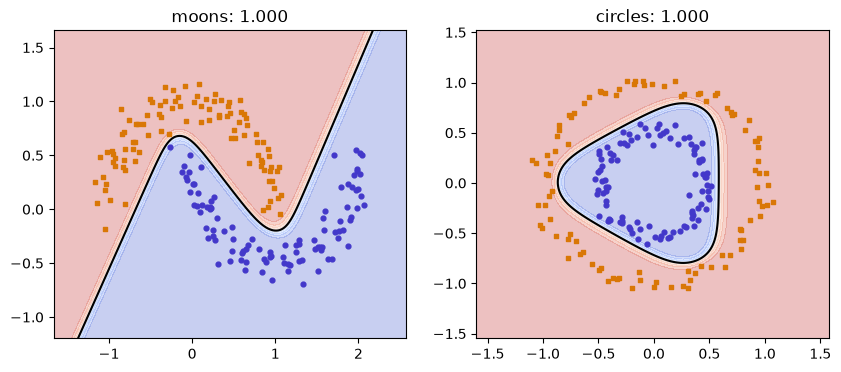

In [19]:
X_c, y_c = make_circles(n_samples=200, noise=0.05, factor=0.5, random_state=0)
Xc_t, yc_t = torch.tensor(X_c, dtype=torch.float32), torch.tensor(y_c, dtype=torch.float32)

### START CODE HERE ###
torch.manual_seed(0)
model_circles = nn.Sequential(nn.Linear(2, 3), nn.Sigmoid(), nn.Linear(3, 1))
losses_circles = train(model_circles, Xc_t, yc_t, lr=5.0, n_epochs=2000)
acc_circles = accuracy(model_circles, Xc_t, yc_t)
### END CODE HERE ###

print("accuracy on the circles:", acc_circles)
assert acc_circles > 0.95, "3 hidden neurons are enough to surround the inner circle"
print("Exercise validated!")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_boundary(model_moons, X_m, y_m, f"moons: {acc_moons:.3f}", axes[0])
plot_boundary(model_circles, X_c, y_c, f"circles: {acc_circles:.3f}", axes[1])
plt.show()

💡 **Explication (exercice 16) : les cercles**

Le cercle intérieur (classe 1) est entouré par le grand cercle (classe 0) : **aucune droite** ne peut l'isoler. Résultat : **1.0**. Les 3 neurones cachés tracent 3 droites, et le neurone de sortie garde la zone qui est du « bon côté » des trois : un triangle arrondi autour du petit cercle.

**What we see.** On the circles, the three hidden neurons draw three lines, and the output neuron keeps the
region inside all three: a rounded triangle around the inner circle. The boundary is no longer a line.

# Part D: how many hidden neurons?

### Exercise 17: a loop over the hidden size

For each `h` in `[1, 2, 4, 16]`, create a 2-h-1 network (after `torch.manual_seed(0)`), train it on the
moons (`lr=5.0`, 2000 epochs) and store it in the dictionary `models[h]` and its accuracy in `accs[h]`.

{1: 0.8700000047683716, 2: 0.8899999856948853, 4: 1.0, 16: 1.0}
Exercise validated!


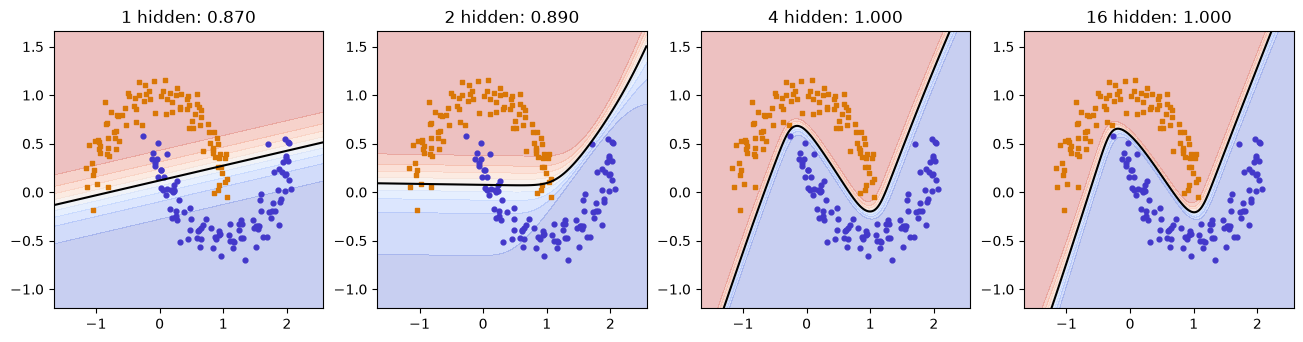

In [20]:
models, accs = {}, {}
for h in [1, 2, 4, 16]:
    ### START CODE HERE ###
    torch.manual_seed(0)                                                        # même départ pour chaque taille
    models[h] = nn.Sequential(nn.Linear(2, h), nn.Sigmoid(), nn.Linear(h, 1))   # réseau 2-h-1
    train(models[h], Xm_t, ym_t, lr=5.0, n_epochs=2000)
    accs[h] = accuracy(models[h], Xm_t, ym_t)
    ### END CODE HERE ###

print(accs)
assert set(accs) == {1, 2, 4, 16}, "one accuracy per hidden size"
assert accs[1] < 0.9, "with 1 hidden neuron the boundary is still (almost) a line"
assert accs[16] > 0.95 and accs[4] > 0.95, "4 and 16 hidden neurons follow the moons"
print("Exercise validated!")
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, h in zip(axes, [1, 2, 4, 16]):
    plot_boundary(models[h], X_m, y_m, f"{h} hidden: {accs[h]:.3f}", ax)
plt.show()

💡 **Explication (exercice 17) : combien de neurones cachés ?**

- `nn.Linear(2, h)` puis `nn.Linear(h, 1)` : la 2e couche doit avoir **autant d'entrées** que la 1re a de neurones ($h$).
- `torch.manual_seed(0)` **dans** la boucle : chaque réseau part du même état aléatoire, la seule différence est $h$.
- On garde chaque modèle dans `models[h]` pour dessiner sa frontière ensuite.

| Neurones cachés $h$ | Accuracy sur les moons | Ce qui se passe |
|---|---|---|
| 1 | 0.87 | une seule droite : c'est une régression logistique déguisée (session 2 : 0.885) |
| 2 | 0.89 | la frontière peut se plier une fois, pas assez |
| 4 | **1.0** | la frontière suit les moons |
| 16 | **1.0** | encore plus souple |

(L'affichage montre `0.8700000047683716` au lieu de 0.87 : c'est un simple arrondi des nombres float32 de PyTorch.)

Plus de neurones = une frontière plus souple. Mais aussi plus de risque d'apprendre le **bruit** des données d'entraînement : pour le savoir, il faut un jeu de test (exercice 19).

**What we see.** One hidden neuron is logistic regression in disguise: a single line, about the accuracy of
session 2. Two neurons can bend the boundary once. From 4 neurons on, the boundary follows the moons. More
neurons give more flexibility, and also more risk of fitting the noise of the training set: we need a test
set to know (Going further, and session 4).

# Going further

### Exercise 18: two hidden layers

Build `deep_model`: `Linear(2, 8)`, `Sigmoid`, `Linear(8, 8)`, `Sigmoid`, `Linear(8, 1)` (after
`torch.manual_seed(0)`), train it on the circles (`lr=5.0`, 2000 epochs), and compute `acc_deep`. Count its
parameters in `n_deep`.

In [21]:
### START CODE HERE ###
torch.manual_seed(0)
deep_model = nn.Sequential(
    nn.Linear(2, 8), nn.Sigmoid(),     # couche cachée 1 : 8 neurones
    nn.Linear(8, 8), nn.Sigmoid(),     # couche cachée 2 : 8 neurones
    nn.Linear(8, 1),                   # sortie : le logit
)
train(deep_model, Xc_t, yc_t, lr=5.0, n_epochs=2000)
acc_deep = accuracy(deep_model, Xc_t, yc_t)
n_deep = sum(p.numel() for p in deep_model.parameters())
### END CODE HERE ###

print("parameters:", n_deep, " accuracy:", acc_deep)
assert n_deep == 8 * 3 + 8 * 9 + 9, "layer by layer: n_out * (n_in + 1)"
assert acc_deep > 0.95, "the deeper network also separates the circles"
print("Exercise validated!")

parameters: 105  accuracy: 1.0
Exercise validated!


💡 **Explication (exercice 18) : deux couches cachées**

Un réseau « profond » (deep) a **plus d'une** couche cachée. Chaque couche combine les sorties de la précédente.

**Compter les paramètres** avec $n^{[l]}(n^{[l-1]} + 1)$, couche par couche (réseau 2-8-8-1) :

| Couche | Calcul | Paramètres |
|---|---|---|
| cachée 1 | $8 \times (2 + 1)$ | 24 |
| cachée 2 | $8 \times (8 + 1)$ | 72 |
| sortie | $1 \times (8 + 1)$ | 9 |
| **Total** | | **105** |

Résultat sur les cercles : **1.0**, comme le réseau à une couche cachée de l'exercice 16 (ce problème est assez simple pour les deux).

### Exercise 19: train and test

Training accuracy says how well the model fits the examples it has seen. To know how it does on **new**
examples, keep some of them aside. With noisier moons (`noise=0.3`, 400 points), split 70 % / 30 % with
`train_test_split(X, y, test_size=0.3, random_state=0)`, train a 2-16-1 network on the training part only
(after `torch.manual_seed(0)`, `lr=5.0`, 2000 epochs) and compute `acc_train` and `acc_test`.

In [22]:
from sklearn.model_selection import train_test_split

X_n, y_n = make_moons(n_samples=400, noise=0.3, random_state=0)
### START CODE HERE ###
# 70 % pour apprendre, 30 % mis de côté pour tester
X_tr, X_te, y_tr, y_te = train_test_split(X_n, y_n, test_size=0.3, random_state=0)
Xtr_t, ytr_t = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)
Xte_t, yte_t = torch.tensor(X_te, dtype=torch.float32), torch.tensor(y_te, dtype=torch.float32)

torch.manual_seed(0)
model_n = nn.Sequential(nn.Linear(2, 16), nn.Sigmoid(), nn.Linear(16, 1))
train(model_n, Xtr_t, ytr_t, lr=5.0, n_epochs=2000)   # entraînement sur la partie train SEULEMENT
acc_train = accuracy(model_n, Xtr_t, ytr_t)
acc_test = accuracy(model_n, Xte_t, yte_t)            # des points que le réseau n'a jamais vus
### END CODE HERE ###

print("train accuracy:", round(acc_train, 3), " test accuracy:", round(acc_test, 3))
assert acc_test > 0.8, "the network should still classify new points well"
assert acc_train > 0.8, "the network should fit the training points well"
print("Exercise validated!")

train accuracy: 0.889  test accuracy: 0.925
Exercise validated!


💡 **Explication (exercice 19) : train et test**

- `train_test_split(X_n, y_n, test_size=0.3, random_state=0)` mélange les 400 points et en met 30 % (120) de côté. Il renvoie, **dans cet ordre** : `X_train, X_test, y_train, y_test`.
- On entraîne **seulement** sur la partie train : le réseau ne voit jamais les points de test.
- `acc_train` : la réussite sur des points déjà vus. `acc_test` : la réussite sur des points **nouveaux**. C'est ce second chiffre qui compte, car c'est ce qui arrivera avec de vraies données.

Résultat : train **0.889**, test **0.925**. Le test est même un peu meilleur que le train : avec seulement 120 points de test, c'est une estimation bruitée, et le bruit des moons (`noise=0.3`) place certains points du mauvais côté quel que soit le modèle. Si le test était très en dessous du train, ce serait le signe que le réseau a appris le bruit par cœur (le surapprentissage, ou overfitting) : on surveillera cet écart à partir de la session 4.

**What we see.** The test accuracy is the number to report: it estimates the performance on new data. Here
it is even a little higher than the training accuracy: with only 120 test points, it is a noisy estimate,
and the noisy moons put some points on the wrong side whatever the model. A test accuracy far below the
training accuracy would be a sign of overfitting; we will monitor this gap from session 4 on.